In [1]:
# import required libraries
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
# load the dataset
df = pd.read_csv("Admission_Prediction_TimeSeries_Ready.csv")

# clean the data
df.columns = df.columns.str.strip()
df["Application_DateTime"] = pd.to_datetime(
    df["Application_DateTime"], errors="coerce"
)
df = df.drop_duplicates()
df = df.dropna(subset=["GRE Score", "TOEFL Score", "CGPA", "Chance of Admit"])

In [3]:
# create admission categories
df["Admission_Status"] = df["Chance of Admit"].apply(
    lambda x: "high chance" if x >= 0.75
    else "medium chance" if x >= 0.50
    else "low chance"
)

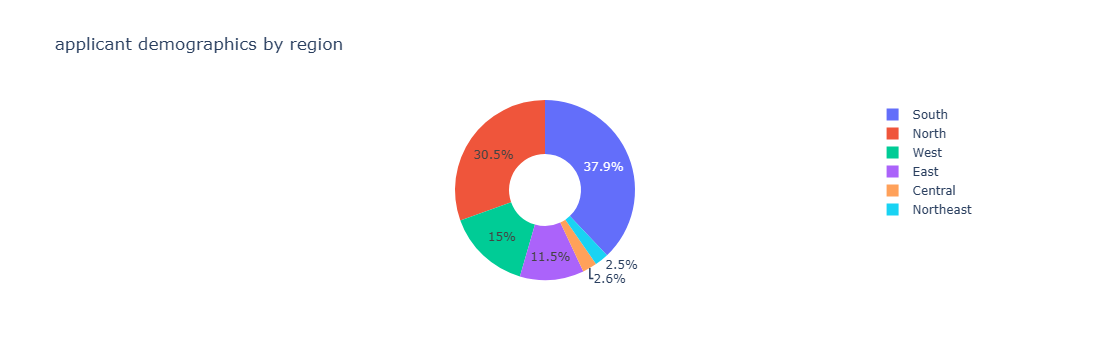

In [4]:
#applicant demographics by region
fig1 = px.pie(
    df,
    names="region",
    title="applicant demographics by region",
    hole=0.4
)
fig1.show()

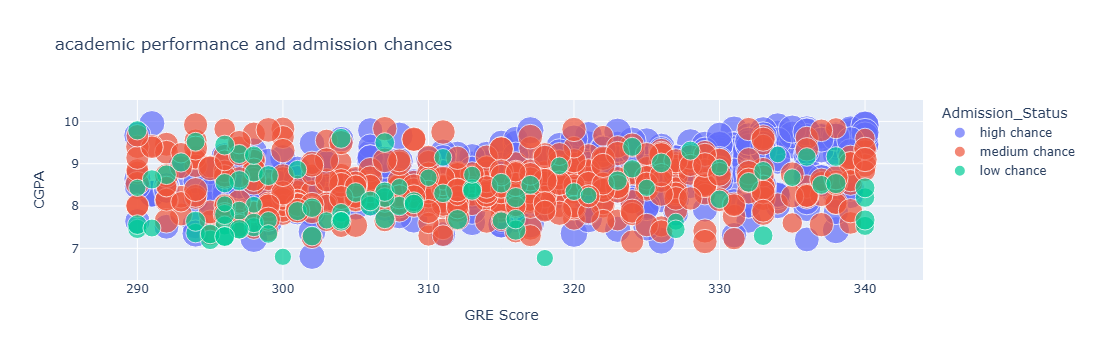

In [5]:
#academic performance comparison
fig2 = px.scatter(
    df,
    x="GRE Score",
    y="CGPA",
    color="Admission_Status",
    size="Chance of Admit",
    hover_data=["TOEFL Score", "University_Name", "Research"],
    title="academic performance and admission chances"
)
fig2.show()

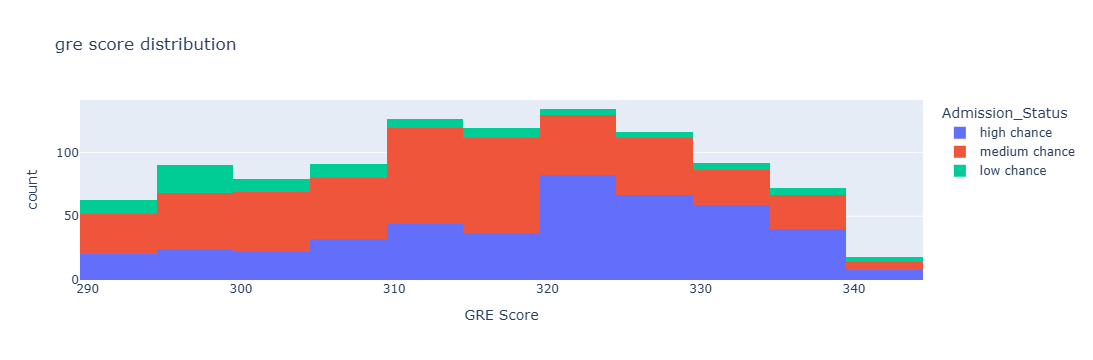

In [6]:
#gre score distribution
fig3 = px.histogram(
    df,
    x="GRE Score",
    color="Admission_Status",
    nbins=20,
    title="gre score distribution"
)
fig3.show()

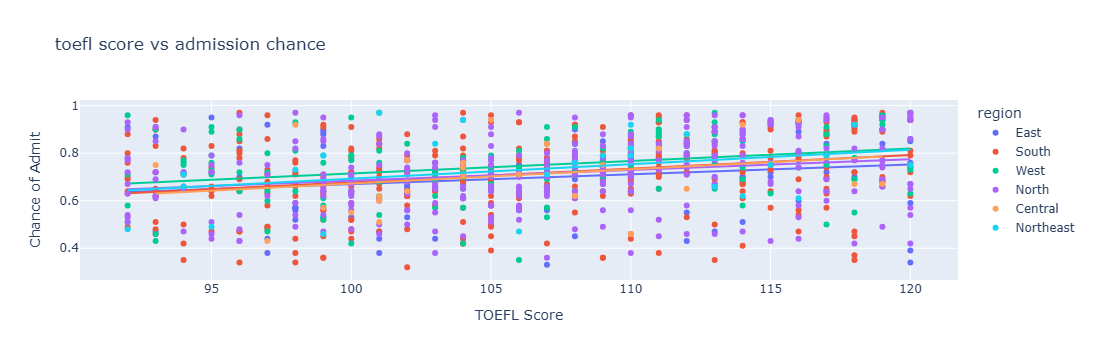

In [7]:
#toefl score vs admission chance
fig4 = px.scatter(
    df,
    x="TOEFL Score",
    y="Chance of Admit",
    color="region",
    hover_data=["GRE Score", "CGPA"],
    trendline="ols",
    title="toefl score vs admission chance"
)
fig4.show()

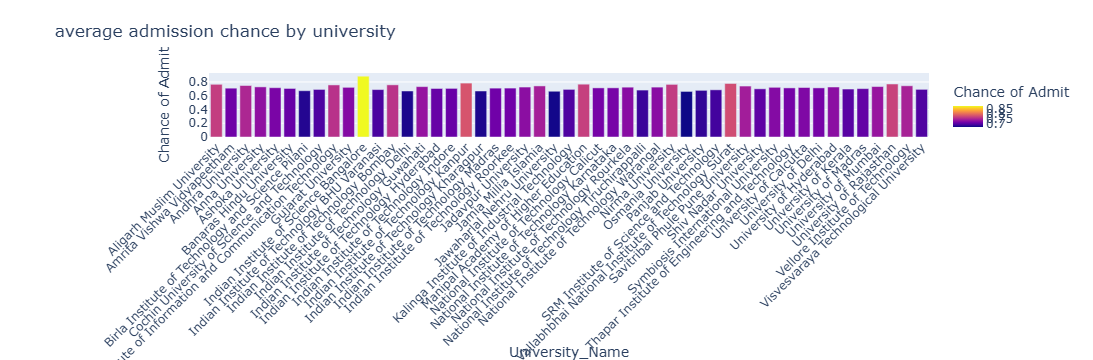

In [8]:
#average admission chance by university
university_data = df.groupby(
    "University_Name", as_index=False
)["Chance of Admit"].mean()

fig5 = px.bar(
    university_data,
    x="University_Name",
    y="Chance of Admit",
    color="Chance of Admit",
    title="average admission chance by university"
)
fig5.update_layout(xaxis_tickangle=-45)
fig5.show()

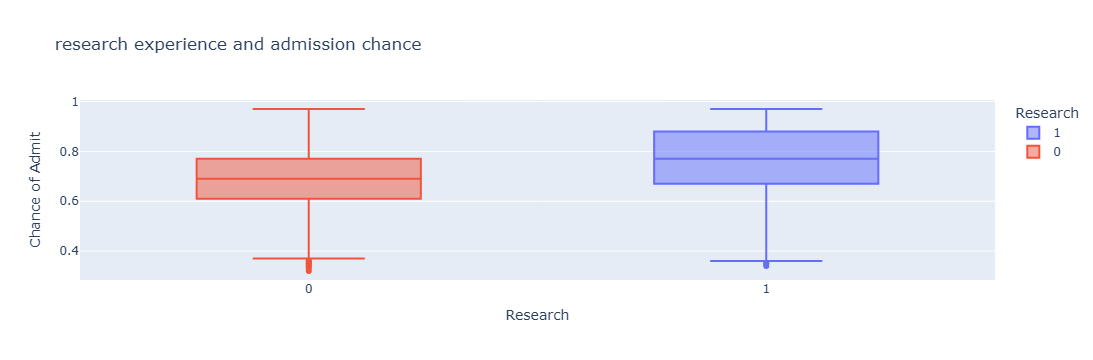

In [9]:
#research experience comparison
fig6 = px.box(
    df,
    x="Research",
    y="Chance of Admit",
    color="Research",
    title="research experience and admission chance"
)
fig6.show()

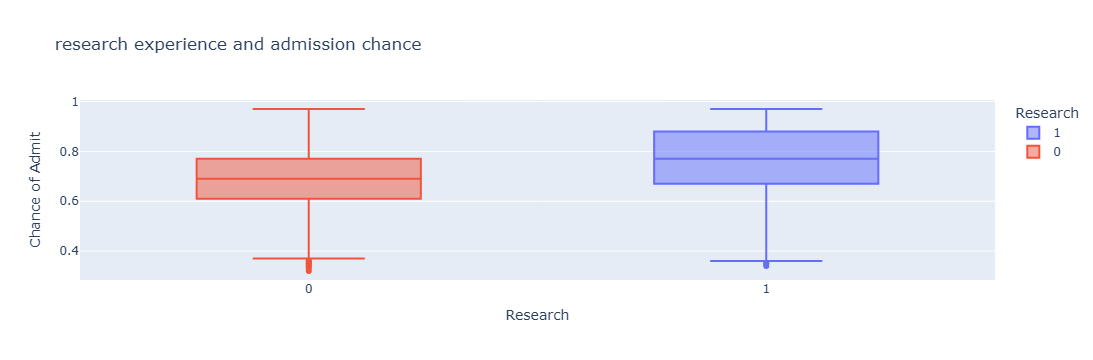

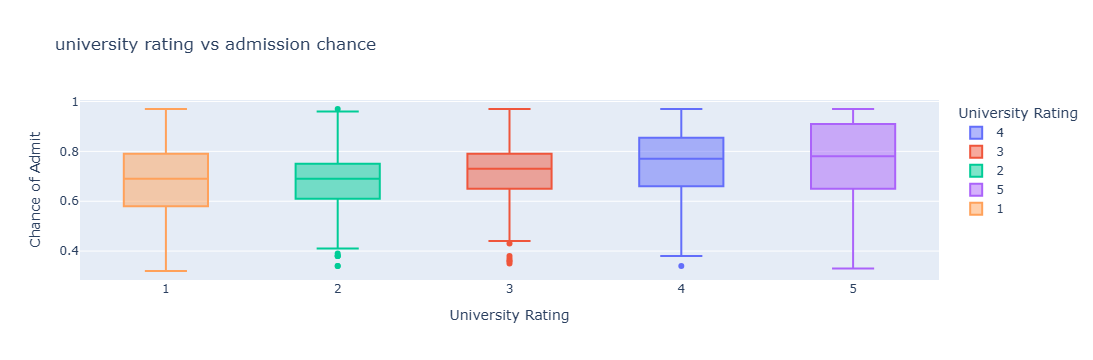

In [10]:
#research experience comparison
fig6 = px.box(
    df,
    x="Research",
    y="Chance of Admit",
    color="Research",
    title="research experience and admission chance"
)
fig6.show()

# 7. university rating comparison
fig7 = px.box(
    df,
    x="University Rating",
    y="Chance of Admit",
    color="University Rating",
    title="university rating vs admission chance"
)
fig7.show()

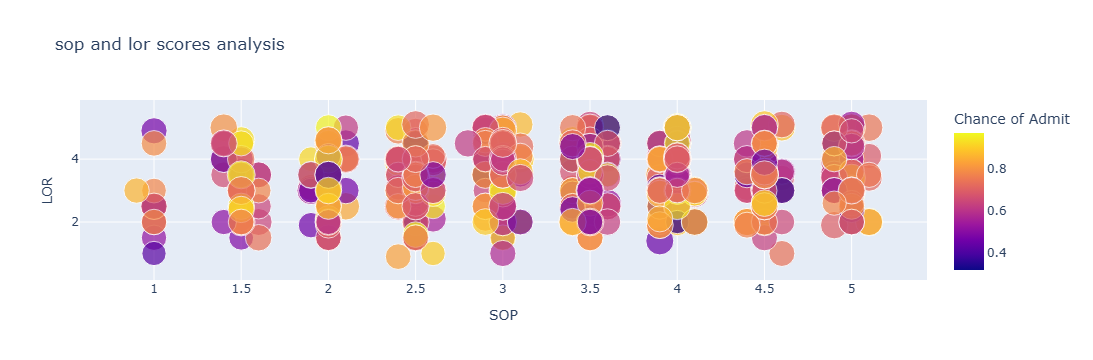

In [11]:
#statement of purpose and recommendation analysis
fig8 = px.scatter(
    df,
    x="SOP",
    y="LOR",
    color="Chance of Admit",
    size="CGPA",
    hover_data=["University_Name", "GRE Score"],
    title="sop and lor scores analysis"
)
fig8.show()

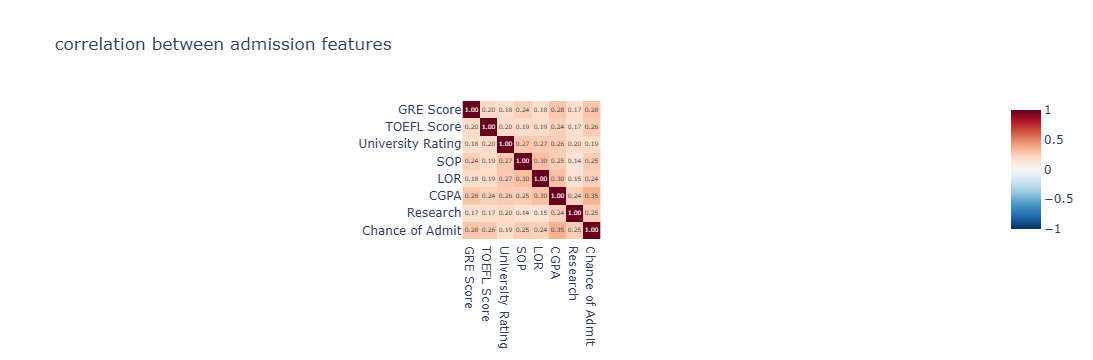

In [12]:
#correlation heatmap
columns = [
    "GRE Score", "TOEFL Score", "University Rating",
    "SOP", "LOR", "CGPA", "Research", "Chance of Admit"
]

correlation = df[columns].corr()

fig10 = px.imshow(
    correlation,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="correlation between admission features"
)
fig10.show()

In [13]:
# key performance indicators
print("total applicants:", len(df))
print("average gre score:", round(df["GRE Score"].mean(), 2))
print("average toefl score:", round(df["TOEFL Score"].mean(), 2))
print("average cgpa:", round(df["CGPA"].mean(), 2))
print("average admission chance:", round(df["Chance of Admit"].mean(), 2))
print("high chance applicants:", (df["Chance of Admit"] >= 0.75).sum())
print("medium chance applicants:", (
    (df["Chance of Admit"] >= 0.50) &
    (df["Chance of Admit"] < 0.75)
).sum())
print("low chance applicants:", (df["Chance of Admit"] < 0.50).sum())

total applicants: 1000
average gre score: 315.96
average toefl score: 106.56
average cgpa: 8.59
average admission chance: 0.72
high chance applicants: 435
medium chance applicants: 471
low chance applicants: 94


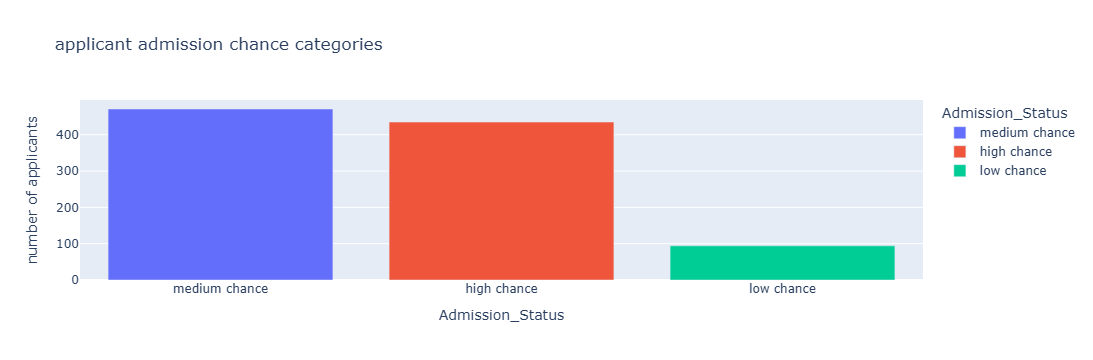

In [14]:
#admission category distribution
fig13 = px.bar(
    df["Admission_Status"].value_counts().reset_index(),
    x="Admission_Status",
    y="count",
    color="Admission_Status",
    title="applicant admission chance categories",
    labels={"count": "number of applicants"}
)
fig13.show()